In [11]:
"""
NEW FLUID MODEL: KEROSENE + GOX + GN2 + (coming later) LOX

METS Feed System — FullFlow model v2
====================================
GOX / kerosene feed lines from regulators to the Hopper torch chamber.
GN2 is not modeled as its own leg yet: PR-REG simply sets the fuel tank
pressure (no GN2 flow losses in steady state).

GOX topology (backbone):
  O-REG outlet → O-TUBE-1 → OMV → O-TUBE-2 → O-INJ (choked) → Chamber

Kerosene topology (backbone):
  Tank (= PR-REG setpoint) → F-TUBE-1 → FMV → F-TUBE-2 → F-ORF (trim) → F-INJ → Chamber

Each TUBE = straight-tube friction (DarcyWeisbach + Colebrook) with its
fittings (bends, tees, unions) folded in as an equivalent length.

Chamber:
  Pc = (mdot_ox + mdot_fuel) * c* / A_throat   ← couples the two legs

Hopper targets (PDR / HopperTorchSizing Excel):
  mdot_ox = 19.29 g/s, mdot_fuel = 10.71 g/s, MR = 1.8, Pc = 200 psia
"""

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from fullflow import (
    Network, State, Balance,
    SteadyState,
    DischargeCoefficient, CompressibleOrifice,
    DarcyWeisbach, Colebrook,
)  # pip install fullflow thermoprop
import thermoprop as tp

script_dir = Path.cwd()
PSI_TO_PA = 6894.76
G_TO_KG = 1e-3

In [12]:
# ─────────────────────────────────────────────────────────────────────
# CUSTOM COMPONENTS / CONVERSIONS
# ─────────────────────────────────────────────────────────────────────
# Converting Cv and K into an effective CdA, so every
# restriction uses FullFlow's built-in DischargeCoefficient (liquid) or
# CompressibleOrifice (gas).

def cv_to_cda(Cv: float) -> float:
    """
    Convert a valve flow coefficient Cv (US, gpm / sqrt(psi)) to an
    equivalent effective area CdA [m^2].

    From Q[gpm] = Cv * sqrt(dP[psi] / SG) and mdot = CdA * sqrt(2 * rho * dP):
        CdA = Cv * 6.309e-5 * sqrt(999 / 6894.76) / sqrt(2) ≈ Cv * 1.70e-5 m^2
    """
    return Cv * 6.309e-5 * np.sqrt(999.0 / PSI_TO_PA) / np.sqrt(2.0)


def k_to_cda(K: float, area: float) -> float:
    """Minor-loss coefficient K (dP = K * rho * v^2 / 2) → effective CdA [m^2]."""
    return area / np.sqrt(K)

In [13]:
# ─────────────────────────────────────────────────────────────────────
# TEST ARTICLE
# ─────────────────────────────────────────────────────────────────────

def make_hopper_torch() -> dict:
    Pc_pa      = 200.0 * PSI_TO_PA    # Hopper PDR
    D_throat_m = 0.1952 * 0.0254      # Hopper PDR
    A_throat   = np.pi * D_throat_m**2 / 4
    mdot_ox    = 19.29 * G_TO_KG      # Hopper PDR
    mdot_fuel  = 10.71 * G_TO_KG      # Hopper PDR
    c_star     = Pc_pa * A_throat / (mdot_ox + mdot_fuel)   # = 887 m/s

    return {
        'name':           'Hopper Torch',
        'target_mdot_ox': mdot_ox,       # [kg/s]
        'target_mdot_fu': mdot_fuel,     # [kg/s]
        'target_MR':      mdot_ox / mdot_fuel,
        'target_Pc':      Pc_pa,         # [Pa]
        'A_throat':       A_throat,      # [m^2]
        'c_star':         c_star,        # [m/s]  
        'CdA_ox_inj':     2.46e-6,       # [m^2]  HopperTorchSizing Testing Pressure Ladder sheet, "OX Injector - O-INJ" CdA (choked)
        'CdA_fu_inj':     3.33e-7,       # [m^2]  # PLACEHOLDER: back-calculated for ~100 psid at 10.71 g/s from Hopper Torch PDR
                                         #        "Injector Parameters" slide (FU orifices ~100 psid). The Testing Pressure Ladder's
                                         #        F-INJ cell (4.79e-7) gives only ~48 psid. Replace with as-built CdA / cold-flow data.
    }


def print_test_article(ta: dict):
    print()
    print("=" * 55)
    print(f"  TEST ARTICLE: {ta['name']}")
    print("=" * 55)
    print(f"  Target mdot ox   = {ta['target_mdot_ox']*1000:.2f} g/s")
    print(f"  Target mdot fuel = {ta['target_mdot_fu']*1000:.2f} g/s")
    print(f"  Target MR        = {ta['target_MR']:.2f}")
    print(f"  Target Pc        = {ta['target_Pc']/PSI_TO_PA:.1f} psia")
    print(f"  Throat D         = {np.sqrt(4*ta['A_throat']/np.pi)/0.0254:.4f} in")
    print(f"  c* (actual)      = {ta['c_star']:.1f} m/s")
    print("=" * 55)

In [14]:
# ─────────────────────────────────────────────────────────────────────
# FLUID PROPERTY HELPERS
# ─────────────────────────────────────────────────────────────────────
GOX_GAMMA = 1.40      # ideal diatomic gas value
GOX_R     = 259.8     # [J/kg-K] 8314 / 32.00 (O2 molar mass, CoolProp);
RHO_KERO  = 800.0     # [kg/m^3] # PLACEHOLDER: typical RP-1 / Jet-A at ~20 C (~800-820). 
T_AMB     = 293.0     # [K] HopperTorchSizing Testing Pressure Ladder sheet (OX / FU temperature = 293 K)
MU_GOX    = 2.1e-5    # [Pa-s] CoolProp O2 at 293 K, 1-4.5 MPa (2.05-2.13e-5)
MU_KERO   = 1.6e-3    # [Pa-s] # PLACEHOLDER: typical kerosene at 20 C (~2 cSt); CoolProp n-dodecane gives 1.53e-3

# GOX is treated as an ideal gas everywhere (rho = P / R T). At ~650 psia
# real O2 is ~3% denser (Z ≈ 0.97); good enough for a first model.

def gox_density(P: State, T: float = T_AMB) -> State:
    """Live ideal-gas density State: recomputed whenever P changes."""
    return P / (GOX_R * T)


def real_gox_density(pressure_pa: float, temperature: float = T_AMB) -> float:
    """Real-gas check value via ThermoProp/CoolProp (not used in the solve)."""
    return tp.Fluid('oxygen', pressure=pressure_pa, temperature=temperature).density

In [15]:
# ─────────────────────────────────────────────────────────────────────
# STAND HARDWARE (shared by every test article)
# ─────────────────────────────────────────────────────────────────────
TUBE_ID = (0.25 - 2 * 0.035) * 0.0254     # METS BOM: 1/4" OD x 0.035" WT SS304 seamless tube → ID 4.57 mm
TUBE_AREA      = np.pi * TUBE_ID**2 / 4
TUBE_ROUGHNESS = 1.5e-6   # [m] standard handbook value for drawn stainless tubing (Moody chart tables)

# Loss coefficient per fitting   # PLACEHOLDER: handbook-typical values (Crane TP-410 order of
# magnitude). Replace with fitting-vendor data or cold-flow-measured line dP.
K_FITTING = {
    'bend':       0.25,   # tube bent 90 deg, bend radius ~3 D
    'elbow':      0.75,   # 90 deg AN/JIC elbow fitting
    'tee_run':    0.40,   # flow passing straight through a tee
    'tee_branch': 1.00,   # flow turning through a tee
    'union':      0.08,   # straight union / adapter
}

STAND = {
    # GOX leg
    'P_gox_bottle_psia': 2000.0,
    # Tube runs   # PLACEHOLDER: Measure once METS is built.
    # L = straight length [m], dz = height gain [m], fittings = counts
    'o_segments': [
        {'name': 'O-TUBE-1', 'L': 0.55, 'dz': 0.0,     # O-REG → vent tee → OMV
         'fittings': {'tee_run': 1, 'union': 2}},
        {'name': 'O-TUBE-2', 'L': 0.60, 'dz': 0.0,     # OMV → torch (+~1 ft to torch)
         'fittings': {'bend': 2, 'union': 2}},
    ],
    'omv_Cv':            0.11,    # PLACEHOLDER: matches the Testing Pressure Ladder's assumed valve CdA (2 mm, Cd 0.6 guess
                                  #   = 1.885e-6 m^2). HopperTorchSizing Torch Design V2 sheet lists Cv 0.04. Replace with
                                  #   the AliExpress 1 ksi solenoid datasheet Cv (METS BOM).
    # Fuel leg
    'P_gn2_bottle_psia': 2000.0,
    'f_segments': [               # PLACEHOLDER: same source as o_segments (wall drawing + hand P&ID)
        {'name': 'F-TUBE-1', 'L': 0.95, 'dz': 0.30,    # tank → drain tee → FMV (rises ~1 ft)
         'fittings': {'tee_run': 1, 'bend': 4, 'union': 2}},
        {'name': 'F-TUBE-2', 'L': 0.60, 'dz': 0.0,     # FMV → purge tee → F-ORF
         'fittings': {'tee_run': 1, 'bend': 1, 'union': 2}},
    ],
    'fmv_Cv':            0.11,    # PLACEHOLDER: same basis as omv_Cv (same AliExpress solenoid, METS BOM)
    'CdA_f_orf':         1.62e-6, # [m^2] HopperTorchSizing Testing Pressure Ladder sheet, "Fuel Orifice" CdA
    # Ratings
    'component_rating_psia': 1000.0,   # METS BOM: 1 ksi solenoids, PTs, ball valves (PDR lists solenoid MEOP 1160 psia)
}

In [16]:
# ─────────────────────────────────────────────────────────────────────
# FEED SYSTEM BUILDER
# ─────────────────────────────────────────────────────────────────────

def add_tube_segment(net: Network, seg: dict, P_up: State, rho: State,
                     mu: float, mdot_guess: float):
    """
    NEW. One tube run = straight-tube friction + its fittings, as one pipe:
        P_up → [DarcyWeisbach, f from Colebrook] → P_out
    Fittings are folded in as an equivalent length,
        L_eq = L + K_total * D / f    →    total loss = (f L/D + K_total) rho v^2 / 2
    so one smooth component carries both losses (no extra node).
    Returns the outlet pressure State and the pipe component.
    """
    name  = seg['name']
    P_out = State(P_up.value * 0.995, bounds=(1e4, None))
    mdot  = State(mdot_guess)        # pipe mass flow (solver unknown)
    f     = State(0.02)              # Darcy friction factor (Colebrook output)

    Colebrook(f"{name} friction", net,
        mass_flow=mdot, friction_factor=f, hydraulic_diameter=TUBE_ID,
        dynamic_viscosity=mu, cross_sectional_area=TUBE_AREA,
        roughness=TUBE_ROUGHNESS)

    K_total = sum(K_FITTING[kind] * n for kind, n in seg['fittings'].items())
    L_eq    = seg['L'] + K_total * TUBE_ID / f      # live: updates with f

    PIPE = DarcyWeisbach(name, net,
        mass_flow=mdot, upstream_pressure=P_up, downstream_pressure=P_out,
        length=L_eq, hydraulic_diameter=TUBE_ID, density=rho,
        cross_sectional_area=TUBE_AREA, friction_factor=f,
        height_change=seg['dz'])
    return P_out, PIPE


def build_gox_leg(net: Network, P_reg: State, P_cc: State, stand: dict, ta: dict):
    """GOX: O-REG outlet → O-TUBE-1 → OMV → O-TUBE-2 → O-INJ → chamber."""
    T_ox       = State(T_AMB)
    mdot_scale = 0.02
    seg1, seg2 = stand['o_segments']
    guess      = ta['target_mdot_ox']

    # O-TUBE-1: regulator → OMV inlet
    P_omv_in, PIPE1 = add_tube_segment(net, seg1, P_reg, gox_density(P_reg), MU_GOX, guess)
    P_omv_out = State(P_reg.value * 0.70, bounds=(1e4, None))

    OMV = CompressibleOrifice("OMV", net,
        upstream_total_pressure=P_omv_in, upstream_total_temperature=T_ox,
        downstream_pressure=P_omv_out,   discharge_coefficient=1.0,
        cross_sectional_area=cv_to_cda(stand['omv_Cv']),
        gas_constant=GOX_R,          specific_heat_ratio=GOX_GAMMA)

    # O-TUBE-2: OMV outlet → injector inlet
    P_inj_in, PIPE2 = add_tube_segment(net, seg2, P_omv_out, gox_density(P_omv_out), MU_GOX, guess)

    INJ = CompressibleOrifice("O-INJ", net,
        upstream_total_pressure=P_inj_in, upstream_total_temperature=T_ox,
        downstream_pressure=P_cc,    discharge_coefficient=1.0,
        cross_sectional_area=ta['CdA_ox_inj'],
        gas_constant=GOX_R,          specific_heat_ratio=GOX_GAMMA)

    # ── Node mass balances (continuity): mdot_in = mdot_out ──────────
    Balance("bal_o_omv_in",  net, variable=P_omv_in,
            function=(PIPE1.mass_flow - OMV.mass_flow) / mdot_scale)
    Balance("bal_o_omv_out", net, variable=P_omv_out,
            function=(OMV.mass_flow - PIPE2.mass_flow) / mdot_scale)
    Balance("bal_o_inj_in",  net, variable=P_inj_in,
            function=(PIPE2.mass_flow - INJ.mass_flow) / mdot_scale)

    nodes = {'O-REG outlet': P_reg, 'OMV in': P_omv_in,
             'OMV out': P_omv_out, 'Inj in': P_inj_in}
    branches = {'O-TUBE-1': PIPE1, 'OMV': OMV, 'O-TUBE-2': PIPE2, 'O-INJ': INJ}
    return INJ, nodes, branches


def build_fuel_leg(net: Network, P_tank: State, P_cc: State, stand: dict, ta: dict):
    """Kerosene: tank → F-TUBE-1 → FMV → F-TUBE-2 → F-ORF → F-INJ → chamber."""
    rho        = State(RHO_KERO)
    mdot_scale = 0.01
    seg1, seg2 = stand['f_segments']
    guess      = ta['target_mdot_fu']

    def restriction(name, up, down, CdA):
        return DischargeCoefficient(name, net,
            upstream_pressure=up, downstream_pressure=down, density=rho,
            discharge_coefficient=1.0, cross_sectional_area=CdA)

    # F-TUBE-1: tank → FMV inlet
    P_fmv_in, PIPE1 = add_tube_segment(net, seg1, P_tank, rho, MU_KERO, guess)
    P_fmv_out = State(P_tank.value * 0.98, bounds=(1e4, None))
    FMV = restriction("FMV", P_fmv_in, P_fmv_out, cv_to_cda(stand['fmv_Cv']))

    # F-TUBE-2: FMV outlet → F-ORF inlet
    P_orf_in, PIPE2 = add_tube_segment(net, seg2, P_fmv_out, rho, MU_KERO, guess)
    P_inj_in = State(P_tank.value * 0.96, bounds=(1e4, None))
    ORF = restriction("F-ORF", P_orf_in, P_inj_in, stand['CdA_f_orf'])
    INJ = restriction("F-INJ", P_inj_in, P_cc,     ta['CdA_fu_inj'])

    Balance("bal_f_fmv_in",  net, variable=P_fmv_in,
            function=(PIPE1.mass_flow - FMV.mass_flow) / mdot_scale)
    Balance("bal_f_fmv_out", net, variable=P_fmv_out,
            function=(FMV.mass_flow - PIPE2.mass_flow) / mdot_scale)
    Balance("bal_f_orf_in",  net, variable=P_orf_in,
            function=(PIPE2.mass_flow - ORF.mass_flow) / mdot_scale)
    Balance("bal_f_inj_in",  net, variable=P_inj_in,
            function=(ORF.mass_flow - INJ.mass_flow) / mdot_scale)

    nodes = {'Tank (PR-REG)': P_tank, 'FMV in': P_fmv_in, 'FMV out': P_fmv_out,
             'F-ORF in': P_orf_in, 'Inj in': P_inj_in}
    branches = {'F-TUBE-1': PIPE1, 'FMV': FMV, 'F-TUBE-2': PIPE2, 'F-ORF': ORF, 'F-INJ': INJ}
    return INJ, nodes, branches


def build_mets_system(
    ta:             dict,
    stand:          dict  = STAND,
    P_oreg_psia:    float = 900.0,   # solver initial guess (Hopper Torch TRR GOX reg 900 psig)
    P_tank_psia:    float = 300.0,   # solver initial guess (Testing Pressure Ladder tank 307 psia)
    mode:           str   = 'predict',
) -> tuple[Network, dict]:
    """
    Build the full METS network.

    mode='predict': Fluid Network Model. regulator setpoints are fixed boundaries; solver finds
                    node pressures, Pc, and both mdots.
    mode='design' : Excel Pressure Ladder. regulator setpoints become unknowns with two extra
                    balances (O-INJ mdot = target, F-INJ mdot = target).
                    P_oreg_psia / P_tank_psia are only initial guesses.
    """
    net = Network("METS")

    P_oreg = State(P_oreg_psia * PSI_TO_PA, bounds=(1e5, None))
    P_tank = State(P_tank_psia * PSI_TO_PA, bounds=(1e5, None))
    P_cc   = State(ta['target_Pc'],          bounds=(1e5, None))

    O_INJ, o_nodes, o_br = build_gox_leg(net, P_oreg, P_cc, stand, ta)
    F_INJ, f_nodes, f_br = build_fuel_leg(net, P_tank, P_cc, stand, ta)

    # ── Chamber: Pc = (mdot_ox + mdot_fuel) c* / A_t ─────────────────
    P_scale = 1.0e6
    Balance("bal_chamber", net, variable=P_cc,
            function=((O_INJ.mass_flow + F_INJ.mass_flow) * ta['c_star'] / ta['A_throat']
                      - P_cc) / P_scale)

    # ── Design mode: regulator setpoints solved to hit target mdots ─
    if mode == 'design':
        Balance("bal_target_ox", net, variable=P_oreg,
                function=(O_INJ.mass_flow - ta['target_mdot_ox']) / 0.02)
        Balance("bal_target_fu", net, variable=P_tank,
                function=(F_INJ.mass_flow - ta['target_mdot_fu']) / 0.01)

    states = {
        'P_oreg': P_oreg, 'P_tank': P_tank, 'P_cc': P_cc,
        'mdot_ox': O_INJ.mass_flow, 'mdot_fu': F_INJ.mass_flow,
        'ox_choked': O_INJ.choked,
        'o_nodes': o_nodes, 'f_nodes': f_nodes,
        'o_branches': o_br, 'f_branches': f_br,
    }
    return net, states


def solve(net: Network):
    # Tight tolerances: the default ftol/xtol let the solver stop early.
    SteadyState(net).solve(verbose=False, rtol=1e-6,
                           ftol=1e-14, xtol=1e-14, gtol=1e-14)


def results(states: dict) -> dict:
    mo, mf = states['mdot_ox'].value, states['mdot_fu'].value
    return {'P_oreg_psia': states['P_oreg'].value / PSI_TO_PA,
            'P_tank_psia': states['P_tank'].value / PSI_TO_PA,
            'Pc_psia':     states['P_cc'].value / PSI_TO_PA,
            'mdot_ox_gs':  mo * 1000, 'mdot_fu_gs': mf * 1000,
            'MR':          mo / mf}

In [17]:
# ─────────────────────────────────────────────────────────────────────
# REGULATOR SOLVE + SWEEP
# ─────────────────────────────────────────────────────────────────────

def find_regulator_setpoints(ta: dict, stand: dict = STAND) -> tuple[dict, dict]:
    """Design mode: one solve returns both setpoints that hit the targets."""
    net, states = build_mets_system(ta, stand, mode='design')
    solve(net)
    return results(states), states


def predict(ta: dict, P_oreg_psia: float, P_tank_psia: float,
            stand: dict = STAND) -> tuple[dict, dict]:
    """Prediction mode: given setpoints, what does the stand deliver?"""
    net, states = build_mets_system(ta, stand, P_oreg_psia, P_tank_psia, mode='predict')
    solve(net)
    return results(states), states


def sweep_regulator(ta: dict, which: str, P_sweep_psia: np.ndarray,
                    P_other_psia: float, stand: dict = STAND) -> dict:
    """
    Prediction-mode sweep of one regulator with the other held fixed.
    which = 'ox'   → sweep O-REG, hold tank pressure at P_other_psia
    which = 'fuel' → sweep PR-REG (tank), hold O-REG at P_other_psia
    """
    out = {k: np.full(len(P_sweep_psia), np.nan)
           for k in ('mdot_ox_gs', 'mdot_fu_gs', 'MR', 'Pc_psia')}
    for i, P in enumerate(P_sweep_psia):
        P_ox, P_fu = (P, P_other_psia) if which == 'ox' else (P_other_psia, P)
        try:
            res, _ = predict(ta, P_ox, P_fu, stand)
            for k in out:
                out[k][i] = res[k]
        except Exception:
            pass
    return out

In [18]:
# ─────────────────────────────────────────────────────────────────────
# PLOTTING / PRINTING
# ─────────────────────────────────────────────────────────────────────

def print_summary(label: str, states: dict):
    r = results(states)
    print(f"\n{'='*55}\n  {label}\n{'='*55}")
    print(f"  O-REG setpoint       {r['P_oreg_psia']:8.1f} psia ({r['P_oreg_psia']-14.7:6.1f} psig)")
    print(f"  PR-REG (tank)        {r['P_tank_psia']:8.1f} psia ({r['P_tank_psia']-14.7:6.1f} psig)")
    print(f"  Chamber Pc           {r['Pc_psia']:8.1f} psia")
    print(f"  mdot ox / fuel       {r['mdot_ox_gs']:8.2f} / {r['mdot_fu_gs']:.2f} g/s")
    print(f"  MR                   {r['MR']:8.2f}")
    print(f"  O-INJ choked?        {bool(states['ox_choked'].value)}")
    print("  Node Pressures:")
    for leg in ('o_nodes', 'f_nodes'):
        for name, P in states[leg].items():
            print(f"    {name:<28} {P.value/PSI_TO_PA:8.1f} psia")
    print(f"    {'Chamber':<28} {r['Pc_psia']:8.1f} psia")


def check_limits(states: dict, stand: dict = STAND):
    r = results(states)
    print("\n  Hardware checks:")
    for label, P, bottle in (('O-REG', r['P_oreg_psia'], stand['P_gox_bottle_psia']),
                             ('PR-REG', r['P_tank_psia'], stand['P_gn2_bottle_psia'])):
        ok_rating = P < stand['component_rating_psia']
        ok_bottle = P < bottle
        print(f"    {label}: {P:.0f} psia  | below 1 ksi rating: {ok_rating}"
              f" | below bottle ({bottle:.0f} psia): {ok_bottle}")


def plot_pressure_ladder(states: dict, title: str):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"Pressure Ladder — {title}", fontsize=13, fontweight='bold')
    Pc = states['P_cc'].value / PSI_TO_PA
    for ax, leg, label, color in ((axes[0], 'o_nodes', 'GOx Line', 'steelblue'),
                                  (axes[1], 'f_nodes', 'Kerosene Line', 'firebrick')):
        names = list(states[leg].keys()) + ['Chamber']
        P = [s.value / PSI_TO_PA for s in states[leg].values()] + [Pc]
        bars = ax.barh(names[::-1], P[::-1], color=color, edgecolor='black', linewidth=0.8)
        for bar, val in zip(bars, P[::-1]):
            ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
                    f'{val:.1f}', va='center', fontsize=9)
        ax.set_xlim(0, max(P) * 1.12)
        ax.set_xlabel("Pressure [psia]"); ax.set_title(label)
        ax.grid(True, axis='x', alpha=0.4)
    plt.tight_layout()
    plt.savefig(script_dir / "pressure_ladder.png", dpi=150)
    plt.show()


def plot_regulator_sweep(ta, P_sweep_ox, sw_ox, P_req_ox, P_sweep_fu, sw_fu, P_req_fu):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle("Hopper Torch Regulator Sweep", fontsize=13, fontweight='bold')
    for ax, P_sweep, sw, key, target, P_req, label, color in (
        (axes[0], P_sweep_ox, sw_ox, 'mdot_ox_gs', ta['target_mdot_ox'], P_req_ox, 'O-REG', 'steelblue'),
        (axes[1], P_sweep_fu, sw_fu, 'mdot_fu_gs', ta['target_mdot_fu'], P_req_fu, 'PR-REG (tank)', 'firebrick'),
    ):
        ax.plot(P_sweep, sw[key], color=color, linewidth=2, label='mdot')
        ax.axhline(target * 1000, color='black', linestyle='--', linewidth=1.2,
                   label=f'Target {target*1000:.2f} g/s')
        ax.axvline(P_req, color='green', linewidth=1.2, label=f'Design setpoint {P_req:.0f} psia')
        ax.set_xlabel(f"{label} setpoint [psia]"); ax.set_ylabel("Mass flow [g/s]")
        ax2 = ax.twinx()
        ax2.plot(P_sweep, sw['MR'], color='gray', linestyle=':', linewidth=1.5, label='MR')
        ax2.axhline(ta['target_MR'], color='gray', linewidth=0.8)
        ax2.set_ylabel("MR", color='gray')
        ax.set_title(f"{label} swept, other regulator held at design setpoint")
        ax.legend(loc='upper left', fontsize=9); ax.grid(True, alpha=0.4)
    plt.tight_layout()
    plt.savefig(script_dir / "regulator_sweep.png", dpi=150)
    plt.show()


  TEST ARTICLE: Hopper Torch
  Target mdot ox   = 19.29 g/s
  Target mdot fuel = 10.71 g/s
  Target MR        = 1.80
  Target Pc        = 200.0 psia
  Throat D         = 0.1952 in
  c* (actual)      = 887.5 m/s

  DESIGN MODE — required regulator setpoints
  O-REG setpoint          658.6 psia ( 643.9 psig)
  PR-REG (tank)           301.6 psia ( 286.9 psig)
  Chamber Pc              200.0 psia
  mdot ox / fuel          19.29 / 10.71 g/s
  MR                       1.80
  O-INJ choked?        True
  Node Pressures:
    O-REG outlet                    658.6 psia
    OMV in                          654.1 psia
    OMV out                         465.3 psia
    Inj in                          458.3 psia
    Tank (PR-REG)                   301.6 psia
    FMV in                          300.9 psia
    FMV out                         297.9 psia
    F-ORF in                        297.7 psia
    Inj in                          293.8 psia
    Chamber                         200.0 psia

  Hardware

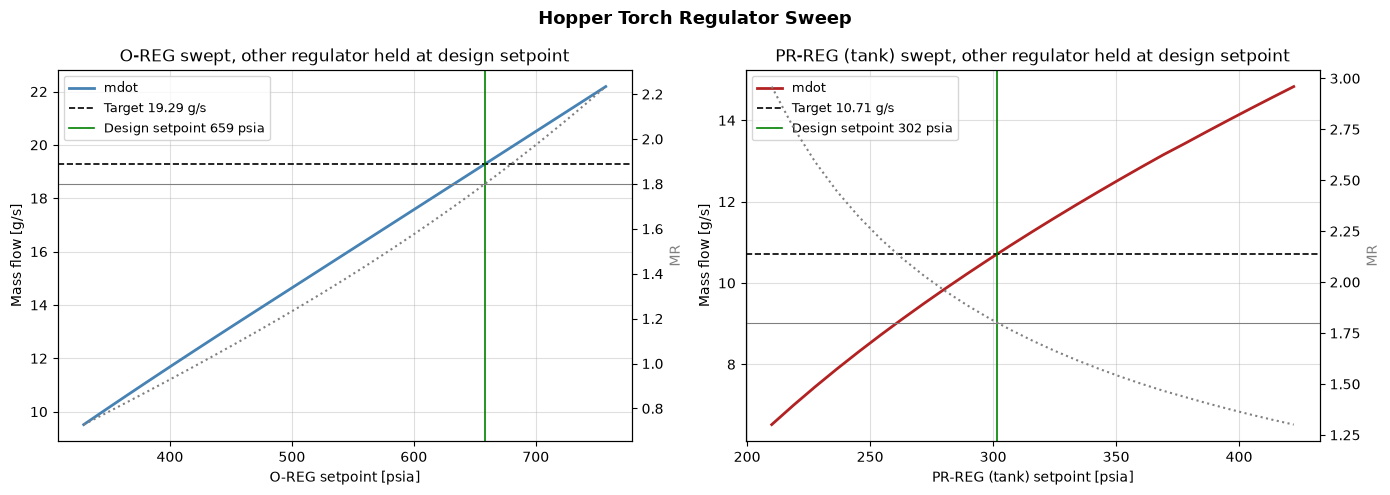

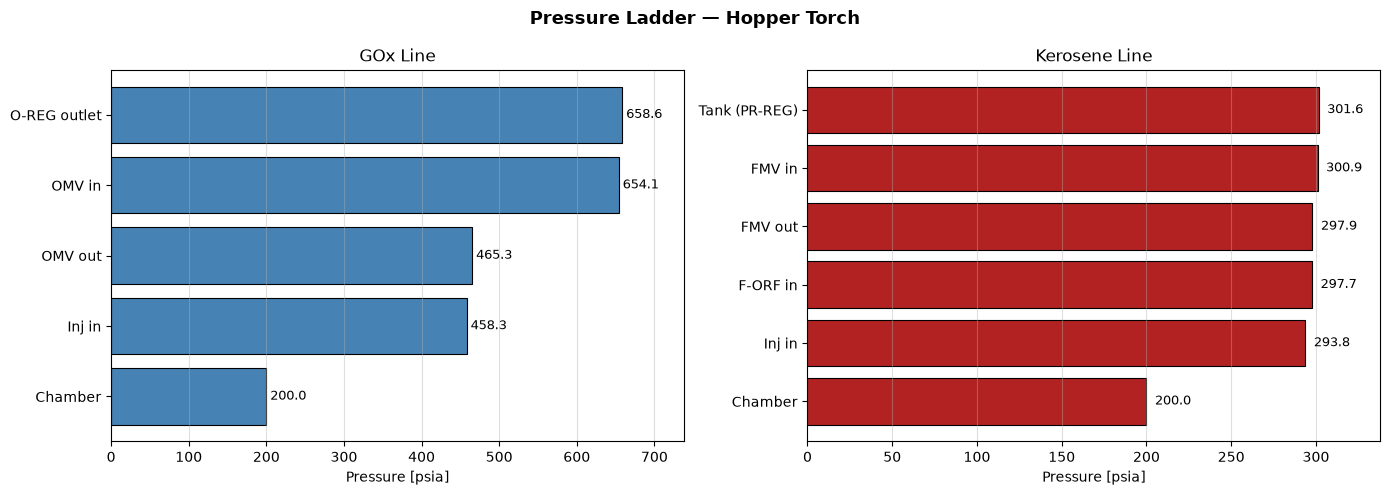

In [19]:
# ─────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────
if __name__ == "__main__":

    # STEP 1 — Test article targets
    TA = make_hopper_torch()
    print_test_article(TA)

    # STEP 2 — Design mode: what we set regulators to in order to hit the targets (pressure ladder)
    design, d_states = find_regulator_setpoints(TA)
    print_summary("DESIGN MODE — required regulator setpoints", d_states)
    check_limits(d_states)
    print("\n  !! Cv, line K and fuel injector CdA are placeholders (# PLACEHOLDER) !!")

    # STEP 3a — Self-check: predicting at the exact design setpoints must
    #           return the targets. If not, something in the network is wrong.
    check, _ = predict(TA, design['P_oreg_psia'], design['P_tank_psia'])
    print(f"\n  Self-check (predict at design setpoints): "
          f"ox {check['mdot_ox_gs']:.2f} g/s, fuel {check['mdot_fu_gs']:.2f} g/s, "
          f"MR {check['MR']:.3f}, Pc {check['Pc_psia']:.1f} psia")

    # STEP 3b — Prediction mode at rounded, real-world setpoints
    P_ox_set = round(design['P_oreg_psia'] / 5) * 5
    P_fu_set = round(design['P_tank_psia'] / 5) * 5
    pred, p_states = predict(TA, P_ox_set, P_fu_set)
    print_summary(f"PREDICTION MODE — regs set to {P_ox_set:.0f} / {P_fu_set:.0f} psia", p_states)

    # STEP 4 — Sweeps around the design point
    P_sweep_ox = np.linspace(0.5, 1.15, 25) * design['P_oreg_psia']
    P_sweep_fu = np.linspace(design['Pc_psia'] + 10, 1.4 * design['P_tank_psia'], 25)
    sw_ox = sweep_regulator(TA, 'ox',   P_sweep_ox, design['P_tank_psia'])
    sw_fu = sweep_regulator(TA, 'fuel', P_sweep_fu, design['P_oreg_psia'])
    plot_regulator_sweep(TA, P_sweep_ox, sw_ox, design['P_oreg_psia'],
                         P_sweep_fu, sw_fu, design['P_tank_psia'])

    # STEP 5 — Pressure ladder at the design point
    plot_pressure_ladder(d_states, "Hopper Torch")